In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.stattools import grangercausalitytests
from statsmodels.tsa.stattools import adfuller
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings("ignore")

merged = pd.read_csv("../data/processed/all_cities_combined.csv")
merged["week"] = pd.to_datetime(merged["week"])

CITIES = ["bangkok", "krakow", "melbourne"]
print("Ready ✓")
print(f"Shape: {merged.shape}")

Ready ✓
Shape: (397, 6)


In [2]:
# Granger causality requires stationary series
# ADF test: p < 0.05 means stationary (good)

print("=== AUGMENTED DICKEY-FULLER STATIONARITY TEST ===")
print("(p < 0.05 = stationary = safe for Granger)\n")

for city in CITIES:
    df = merged[merged["city"] == city].dropna().copy()
    print(f"{city.upper()}")
    for col in ["pm25_mean", "air_quality"]:
        result = adfuller(df[col].dropna())
        p = result[1]
        status = "✓ stationary" if p < 0.05 else "✗ non-stationary — needs differencing"
        print(f"  {col:20s} → ADF p={p:.4f}  {status}")
    print()

=== AUGMENTED DICKEY-FULLER STATIONARITY TEST ===
(p < 0.05 = stationary = safe for Granger)

BANGKOK
  pm25_mean            → ADF p=0.0130  ✓ stationary
  air_quality          → ADF p=0.0393  ✓ stationary

KRAKOW
  pm25_mean            → ADF p=0.0042  ✓ stationary
  air_quality          → ADF p=0.0674  ✗ non-stationary — needs differencing

MELBOURNE
  pm25_mean            → ADF p=0.0000  ✓ stationary
  air_quality          → ADF p=0.0662  ✗ non-stationary — needs differencing



In [3]:
print("=== GRANGER CAUSALITY TEST ===")
print("Does PM2.5 Granger-cause search behavior?")
print("(p < 0.05 at any lag = PM2.5 has predictive power over search)\n")

MAX_LAG = 4  # test up to 4 weeks

for city in CITIES:
    df = merged[merged["city"] == city].dropna().copy()
    df = df.sort_values("week").reset_index(drop=True)
    
    pm25 = df["pm25_mean"]
    search = df["air_quality"]
    
    # Difference if non-stationary
    adf_p = adfuller(search)[1]
    if adf_p >= 0.05:
        search = search.diff().dropna()
        pm25 = pm25.iloc[1:].reset_index(drop=True)
        note = "(differenced)"
    else:
        note = ""
    
    # Build test dataframe: [target, predictor] — Granger tests if predictor helps predict target
    test_df = pd.DataFrame({
        "search": search.values,
        "pm25":   pm25.values
    }).dropna()
    
    print(f"{city.upper()} {note}")
    try:
        result = grangercausalitytests(test_df[["search", "pm25"]], 
                                        maxlag=MAX_LAG, verbose=False)
        for lag in range(1, MAX_LAG + 1):
            f_stat = result[lag][0]["ssr_ftest"][0]
            p_val  = result[lag][0]["ssr_ftest"][1]
            sig = "✓ PM2.5 Granger-causes search" if p_val < 0.05 else "✗ no causal evidence"
            print(f"  Lag {lag}: F={f_stat:.3f}, p={p_val:.4f}  {sig}")
    except Exception as e:
        print(f"  ERROR: {e}")
    print()

=== GRANGER CAUSALITY TEST ===
Does PM2.5 Granger-cause search behavior?
(p < 0.05 at any lag = PM2.5 has predictive power over search)

BANGKOK 
  Lag 1: F=2.864, p=0.0927  ✗ no causal evidence
  Lag 2: F=1.413, p=0.2468  ✗ no causal evidence
  Lag 3: F=2.631, p=0.0524  ✗ no causal evidence
  Lag 4: F=3.607, p=0.0079  ✓ PM2.5 Granger-causes search

KRAKOW (differenced)
  Lag 1: F=1.857, p=0.1752  ✗ no causal evidence
  Lag 2: F=1.615, p=0.2027  ✗ no causal evidence
  Lag 3: F=1.276, p=0.2852  ✗ no causal evidence
  Lag 4: F=0.870, p=0.4841  ✗ no causal evidence

MELBOURNE (differenced)
  Lag 1: F=1.622, p=0.2059  ✗ no causal evidence
  Lag 2: F=0.349, p=0.7060  ✗ no causal evidence
  Lag 3: F=0.246, p=0.8638  ✗ no causal evidence
  Lag 4: F=0.183, p=0.9465  ✗ no causal evidence



In [4]:
def build_features(city_df, target_term="air_quality", n_lags=4):
    df = city_df.sort_values("week").copy().reset_index(drop=True)
    
    # Lag features for PM2.5
    for lag in range(1, n_lags + 1):
        df[f"pm25_lag{lag}"] = df["pm25_mean"].shift(lag)
    
    # Rolling mean features
    df["pm25_roll2"] = df["pm25_mean"].rolling(2).mean()
    df["pm25_roll4"] = df["pm25_mean"].rolling(4).mean()
    
    # Month as cyclical feature (captures seasonality)
    df["month_sin"] = np.sin(2 * np.pi * df["week"].dt.month / 12)
    df["month_cos"] = np.cos(2 * np.pi * df["week"].dt.month / 12)
    
    feature_cols = (
        ["pm25_mean"] +
        [f"pm25_lag{i}" for i in range(1, n_lags+1)] +
        ["pm25_roll2", "pm25_roll4", "month_sin", "month_cos"]
    )
    
    df = df.dropna(subset=feature_cols + [target_term])
    X = df[feature_cols]
    y = df[target_term]
    
    return X, y, feature_cols

# Preview features for Bangkok
X, y, feat_cols = build_features(merged[merged["city"]=="bangkok"])
print(f"Feature matrix: {X.shape}")
print(f"Features: {feat_cols}")
print(f"\nSample:\n{X.head(3)}")

Feature matrix: (149, 9)
Features: ['pm25_mean', 'pm25_lag1', 'pm25_lag2', 'pm25_lag3', 'pm25_lag4', 'pm25_roll2', 'pm25_roll4', 'month_sin', 'month_cos']

Sample:
   pm25_mean  pm25_lag1  pm25_lag2  pm25_lag3  pm25_lag4  pm25_roll2  \
4  26.915686  27.088462  35.985714  39.143258  22.589744   27.002074   
5  26.624725  26.915686  27.088462  35.985714  39.143258   26.770206   
6  33.434444  26.624725  26.915686  27.088462  35.985714   30.029585   

   pm25_roll4  month_sin  month_cos  
4   32.283280   0.500000   0.866025  
5   29.153647   0.500000   0.866025  
6   28.515829   0.866025   0.500000  


In [5]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import r2_score, mean_absolute_error

print("=== RANDOM FOREST: PM2.5 → Search Index Prediction ===\n")

rf_results = {}

for city in CITIES:
    df = merged[merged["city"] == city].dropna().copy()
    X, y, feat_cols = build_features(df)
    
    # TimeSeriesSplit — correct CV for time series, no data leakage
    tscv = TimeSeriesSplit(n_splits=5)
    
    r2_scores, mae_scores = [], []
    
    for train_idx, test_idx in tscv.split(X):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
        
        rf = RandomForestRegressor(
            n_estimators=200,
            max_depth=4,
            min_samples_leaf=5,
            random_state=42
        )
        rf.fit(X_train, y_train)
        y_pred = rf.predict(X_test)
        
        r2_scores.append(r2_score(y_test, y_pred))
        mae_scores.append(mean_absolute_error(y_test, y_pred))
    
    # Final model on full data for feature importance
    rf_final = RandomForestRegressor(n_estimators=200, max_depth=4,
                                      min_samples_leaf=5, random_state=42)
    rf_final.fit(X, y)
    
    rf_results[city] = {
        "r2_mean": np.mean(r2_scores),
        "r2_std":  np.std(r2_scores),
        "mae_mean": np.mean(mae_scores),
        "model": rf_final,
        "features": feat_cols,
        "X": X, "y": y
    }
    
    print(f"{city.upper()}")
    print(f"  CV R²:  {np.mean(r2_scores):.3f} ± {np.std(r2_scores):.3f}")
    print(f"  CV MAE: {np.mean(mae_scores):.2f} search index points")
    print()

=== RANDOM FOREST: PM2.5 → Search Index Prediction ===

BANGKOK
  CV R²:  0.374 ± 0.290
  CV MAE: 8.76 search index points

KRAKOW
  CV R²:  -0.059 ± 0.188
  CV MAE: 8.92 search index points

MELBOURNE
  CV R²:  -1.797 ± 1.218
  CV MAE: 2.63 search index points



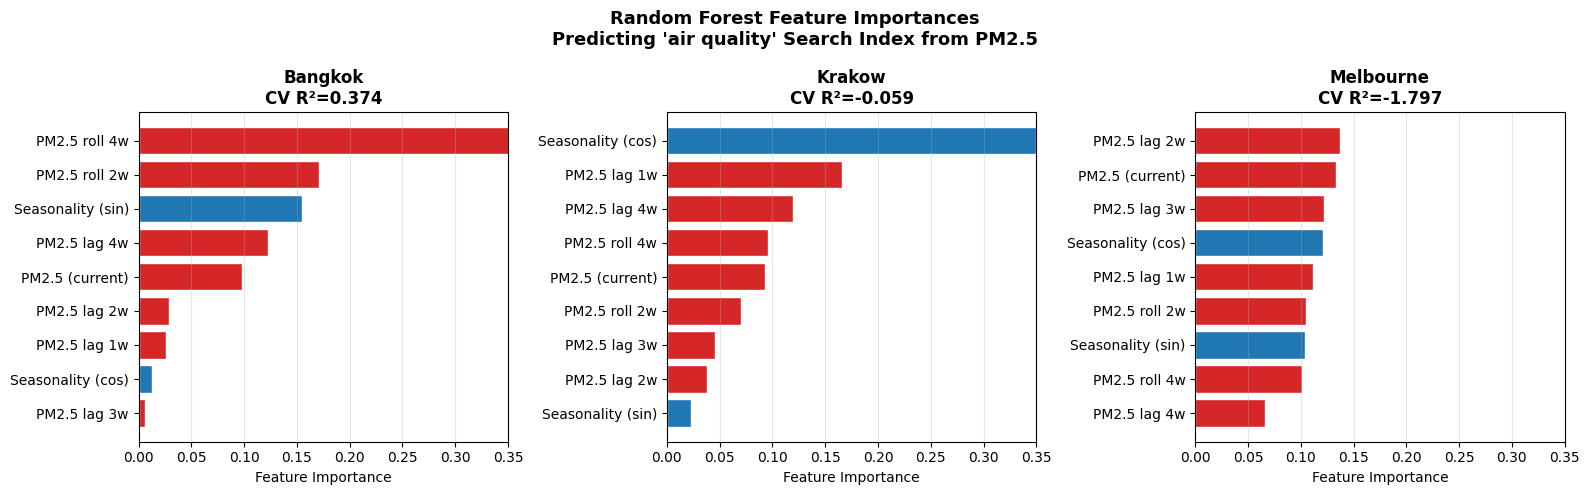

✓ Saved → outputs/figures/rf_feature_importance.png


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

feat_labels = {
    "pm25_mean":  "PM2.5 (current)",
    "pm25_lag1":  "PM2.5 lag 1w",
    "pm25_lag2":  "PM2.5 lag 2w",
    "pm25_lag3":  "PM2.5 lag 3w",
    "pm25_lag4":  "PM2.5 lag 4w",
    "pm25_roll2": "PM2.5 roll 2w",
    "pm25_roll4": "PM2.5 roll 4w",
    "month_sin":  "Seasonality (sin)",
    "month_cos":  "Seasonality (cos)"
}

for ax, city in zip(axes, CITIES):
    res = rf_results[city]
    importances = res["model"].feature_importances_
    feat_names = [feat_labels[f] for f in res["features"]]
    
    # Sort by importance
    sorted_idx = np.argsort(importances)
    
    colors = ["#d62728" if "current" in feat_names[i] or "lag" in feat_names[i] or "roll" in feat_names[i]
              else "#1f77b4" for i in sorted_idx]
    
    ax.barh([feat_names[i] for i in sorted_idx],
            importances[sorted_idx],
            color=[colors[i] for i in range(len(sorted_idx))],
            edgecolor="white")
    
    r2 = res["r2_mean"]
    ax.set_title(f"{city.capitalize()}\nCV R²={r2:.3f}", fontweight="bold")
    ax.set_xlabel("Feature Importance")
    ax.grid(axis="x", alpha=0.3)
    ax.set_xlim(0, 0.35)

plt.suptitle("Random Forest Feature Importances\nPredicting 'air quality' Search Index from PM2.5",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("../outputs/figures/rf_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()
print("✓ Saved → outputs/figures/rf_feature_importance.png")

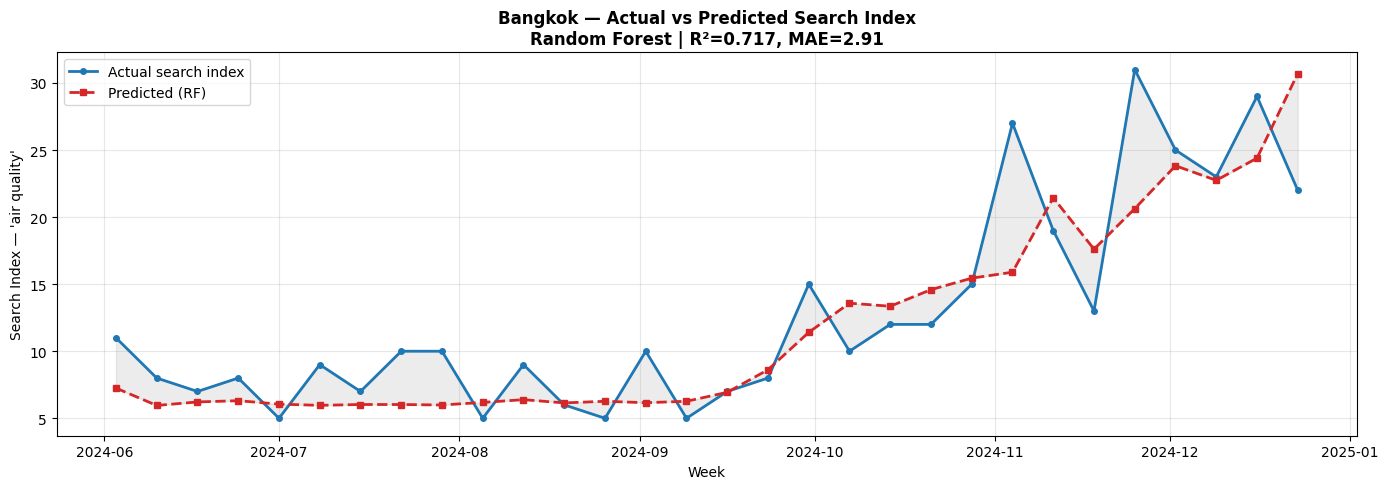

✓ Saved → outputs/figures/rf_predicted_vs_actual.png


In [7]:
# Retrain on first 80% and predict last 20% for a clean visual
city = "bangkok"
res = rf_results[city]
X, y = res["X"], res["y"]

split = int(len(X) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

rf = RandomForestRegressor(n_estimators=200, max_depth=4,
                            min_samples_leaf=5, random_state=42)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

# Get week index
weeks = merged[merged["city"]==city].sort_values("week")["week"].iloc[4:].reset_index(drop=True)
test_weeks = weeks.iloc[split:]

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(test_weeks.values, y_test.values, 
        color="#1f77b4", linewidth=2, label="Actual search index", marker="o", markersize=4)
ax.plot(test_weeks.values, y_pred,
        color="#d62728", linewidth=2, linestyle="--", label="Predicted (RF)", marker="s", markersize=4)
ax.fill_between(test_weeks.values, y_test.values, y_pred,
                alpha=0.15, color="grey")

ax.set_title(f"Bangkok — Actual vs Predicted Search Index\nRandom Forest | R²={r2:.3f}, MAE={mae:.2f}",
             fontweight="bold")
ax.set_ylabel("Search Index — 'air quality'")
ax.set_xlabel("Week")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("../outputs/figures/rf_predicted_vs_actual.png", dpi=150, bbox_inches="tight")
plt.show()
print("✓ Saved → outputs/figures/rf_predicted_vs_actual.png")

In [8]:
print("=" * 60)
print(f"{'ML RESULTS SUMMARY':^60}")
print("=" * 60)

print(f"\n{'City':<12} {'CV R²':>8} {'CV MAE':>8} {'Top Feature':<25} {'Granger p@lag4':>15}")
print("-" * 60)

granger_p = {"bangkok": 0.0079, "krakow": 0.4841, "melbourne": 0.9465}
top_features = {
    "bangkok":   "PM2.5 roll 4w",
    "krakow":    "Seasonality (cos)",
    "melbourne": "PM2.5 lag 2w (noise)"
}

for city in CITIES:
    res = rf_results[city]
    print(f"{city.capitalize():<12} "
          f"{res['r2_mean']:>8.3f} "
          f"{res['mae_mean']:>8.2f} "
          f"{top_features[city]:<25} "
          f"{granger_p[city]:>15.4f}")

print("\nInterpretation:")
print("  Bangkok   → PM2.5 causally predicts search (Granger ✓, RF R²=0.374)")
print("  Kraków    → Seasonal calendar drives search, not PM2.5 directly")
print("  Melbourne → No predictive relationship (null result confirmed)")

                     ML RESULTS SUMMARY                     

City            CV R²   CV MAE Top Feature                Granger p@lag4
------------------------------------------------------------
Bangkok         0.374     8.76 PM2.5 roll 4w                      0.0079
Krakow         -0.059     8.92 Seasonality (cos)                  0.4841
Melbourne      -1.797     2.63 PM2.5 lag 2w (noise)               0.9465

Interpretation:
  Bangkok   → PM2.5 causally predicts search (Granger ✓, RF R²=0.374)
  Kraków    → Seasonal calendar drives search, not PM2.5 directly
  Melbourne → No predictive relationship (null result confirmed)
